# Classificação da Faixa de Renda de Adultos

**Etapa 2: Modelagem, avaliação e interpretação (classificação)**

**Aluno:** Leonardo Moretti Alva

**Data de entrega:** 04/11/2026

**Dataset:** [Adult Income Census (Kaggle)](https://www.kaggle.com/datasets/anaghakp/adult-income-census), versão do dataset *Adult* do UCI Machine Learning Repository, extraído do Censo dos EUA de 1994.

**Objetivo:** prever se a renda anual de uma pessoa é maior que 50 mil dólares (`>50K`) ou não (`<=50K`). Esta etapa parte do pipeline de pré-processamento construído na Etapa 1 (`projeto_adult_income_eda.ipynb`).

**Roteiro**

1. Seleção e implementação dos modelos: Dummy, Regressão Logística e Random Forest; busca de hiperparâmetros; mudança no pipeline; curva de aprendizado.
2. Avaliação do melhor modelo no conjunto de teste.
3. Interpretação: coeficientes, importâncias e SHAP.
4. Discussão crítica.
5. Conclusão.

**Ferramentas:** Python com Pandas, NumPy, Matplotlib, Seaborn, scikit-learn e SHAP.

## 0. Preparação dos dados (mesmos passos da Etapa 1)

Carregamento, limpeza, remoção de duplicatas e divisão treino/teste são **idênticos à Etapa 1**: mesmo arquivo `adult income1.csv` (na mesma pasta do notebook), mesma categoria `Inválido` para o texto "occupation" na coluna `occupation` e mesmo `random_state`, logo o mesmo conjunto de teste. A única diferença é que o alvo passa a ser numérico: `1` para `>50K` (a classe positiva, que queremos encontrar) e `0` para `<=50K`. Assim, F1, precision e recall sabem qual é a classe positiva.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap  # já vem instalado no Colab; localmente: pip install shap

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#b4b2a9'  # cores usadas nos gráficos

In [2]:
# Carregamento e limpeza iguais à Etapa 1 (o CSV do Kaggle fica na mesma pasta do notebook).
data = pd.read_csv('adult income1.csv', na_values='?')                     # '?' vira NaN
data.columns = data.columns.str.replace('.', '_', regex=False)               # 'education.num' -> 'education_num'
data['occupation'] = data['occupation'].replace('occupation', 'Inválido')  # valor inválido vira categoria própria
data = data.drop_duplicates().reset_index(drop=True)                         # remove as 65 duplicatas

# Alvo numérico: 1 = '>50K' (classe positiva), 0 = '<=50K'.
X = data.drop(columns='income')
y = (data['income'] == '>50K').astype(int)

# Mesma divisão estratificada 80/20 da Etapa 1.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('Treino:', X_train.shape, '| Teste:', X_test.shape, '| % de >50K no treino:', round(y_train.mean() * 100, 2))

Treino: (25505, 11) | Teste: (6377, 11) | % de >50K no treino: 24.07


### 0.1 Pipeline de pré-processamento (o mesmo da Etapa 1)

| Grupo de variáveis | Tratamento (decidido na EDA) |
|---|---|
| `age`, `education_num` | `StandardScaler` (não há ausentes) |
| 7 categóricas: `workclass`, `marital_status`, `occupation`, `relationship`, `race`, `sex`, `native_country` | imputação da categoria `Desconhecido` + One-Hot Encoding com `handle_unknown='ignore'` |
| `education`, `fnlwgt` | descartadas (redundante / peso amostral) |

Há dois ajustes que **não mudam os dados transformados**:

- `verbose_feature_names_out=False` no `ColumnTransformer` deixa os nomes das colunas legíveis (`marital_status_Married-civ-spouse` em vez de `categorical__marital_status_Married-civ-spouse`). A Seção 3 usa esses nomes para interpretar o modelo.
- O pipeline é montado por uma função com o parâmetro `min_frequency`. Ele fica desligado (pipeline idêntico ao da Etapa 1) até a Seção 1.4, onde é usado para a mudança no pipeline.

Como o pré-processamento fica **dentro** do `Pipeline`, a validação cruzada reajusta imputação, escala e encoding em cada fold, usando só os dados de treino daquele fold. Assim não há vazamento de dados.

In [3]:
numeric_features = ['age', 'education_num']
categorical_features = ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
# 'education' e 'fnlwgt' não aparecem em nenhuma lista, então o ColumnTransformer as descarta.


def criar_preprocessador(min_frequency=None):
    # Pré-processamento da Etapa 1. Com min_frequency=None é idêntico ao da Etapa 1. Com um número,
    # as categorias mais raras que isso no treino são agrupadas numa única coluna (mudança da Seção 1.4).
    if min_frequency is None:
        onehot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    else:
        onehot = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=min_frequency, sparse_output=False)
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Desconhecido')),
        ('onehot', onehot)
    ])
    return ColumnTransformer([
        ('numeric', StandardScaler(), numeric_features),
        ('categorical', categorical_pipeline, categorical_features)
    ], verbose_feature_names_out=False)


def criar_modelo(classificador, min_frequency=None):
    # Pipeline completo: pré-processamento + classificador.
    return Pipeline([('preprocessor', criar_preprocessador(min_frequency)), ('classifier', classificador)])


print('Colunas após o pré-processamento:', criar_preprocessador().fit_transform(X_train).shape[1])

Colunas após o pré-processamento: 89


## 1. Seleção e implementação dos modelos

### 1.1 Métrica de desempenho e estratégia de validação

**Métrica escolhida: F1-score da classe `>50K`**, usada em todas as comparações desta seção.

- As classes são desbalanceadas (76% `<=50K` e 24% `>50K`). A acurácia premia um modelo que ignora a classe minoritária; o Dummy, logo abaixo, mostra isso.
- O F1 é a média harmônica entre **precision** (das pessoas que o modelo diz ganharem `>50K`, quantas realmente ganham) e **recall** (das pessoas que ganham `>50K`, quantas o modelo encontra). Ele só é alto quando as duas são altas.
- O problema não define um custo diferente para falsos positivos e falsos negativos, então uma métrica que equilibra os dois é a escolha neutra.

**Validação:** `StratifiedKFold` com 5 folds, aplicado **só no conjunto de treino**. Cada configuração é treinada 5 vezes (em 4/5 do treino) e avaliada no 1/5 restante; reportamos a média e o desvio padrão dos 5 F1. A estratificação mantém 24% de `>50K` em cada fold. O conjunto de teste só é usado na Seção 2, para dar uma estimativa honesta do desempenho final.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def avaliar(modelo):
    # F1 médio e desvio padrão na validação cruzada (apenas dados de treino).
    scores = cross_val_score(modelo, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
    return scores.mean(), scores.std()


def resumo(grid):
    # F1 médio e desvio padrão da melhor combinação encontrada por um GridSearchCV.
    i = grid.best_index_
    return grid.cv_results_['mean_test_score'][i], grid.cv_results_['std_test_score'][i]

### 1.2 Os três modelos com hiperparâmetros padrão

| Modelo | Como funciona | Por que foi escolhido |
|---|---|---|
| **Dummy** (`most_frequent`) | Sempre prevê a classe mais comum (`<=50K`), sem olhar as features | Linha de base: um modelo útil precisa superá-lo |
| **Regressão Logística** (linear com regularização) | Faz uma soma ponderada das features e a transforma em probabilidade com a função sigmoide. Usa regularização **L2** (padrão do sklearn), que penaliza coeficientes grandes; a força é controlada por `C` | Simples, rápida e interpretável pelos coeficientes |
| **Random Forest** (ensemble de árvores) | Treina muitas árvores de decisão, cada uma com uma amostra *bootstrap* das linhas e um subconjunto aleatório de features por divisão; a previsão é a votação das árvores (*bagging*) | Captura relações não lineares e interações (ex.: casado **e** com ensino superior) sem criá-las à mão; a média de muitas árvores reduz o sobreajuste de uma árvore isolada |

Nos dois modelos reais usamos `class_weight='balanced'` (proposto na Etapa 1): no treino, cada erro na classe `>50K` pesa cerca de 3 vezes mais, o que compensa o desbalanceamento.

In [5]:
modelos_base = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'Regressão Logística (padrão)': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest (padrão)': RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
}

resultados = {}  # guarda (F1 médio, desvio) de cada modelo avaliado nesta seção
for nome, classificador in modelos_base.items():
    resultados[nome] = avaliar(criar_modelo(classificador))

display(pd.DataFrame(resultados, index=['F1 médio (CV)', 'desvio padrão']).T.round(3))

# Acurácia do Dummy, só para mostrar por que ela não serve como métrica aqui.
acuracia_dummy = cross_val_score(criar_modelo(DummyClassifier(strategy='most_frequent')),
                                 X_train, y_train, cv=cv, scoring='accuracy').mean()
print(f'Acurácia do Dummy na validação cruzada: {acuracia_dummy:.3f}')

,F1 médio (CV),desvio padrão
Dummy,0.000,0.000
Regressão Logística (padrão),0.653,0.004
Random Forest (padrão),0.624,0.006


Acurácia do Dummy na validação cruzada: 0.759


**Interpretação**

- **Dummy:** F1 = 0, porque ele nunca prevê `>50K` e, portanto, não encontra nenhuma pessoa da classe positiva (recall = 0). Mesmo assim, a acurácia dele é **0,759**, exatamente a proporção de `<=50K`. Isso confirma na prática por que a acurácia não serve como métrica neste problema.
- **Regressão Logística (0,653)** supera muito a linha de base já com os hiperparâmetros padrão.
- **Random Forest (0,624)** fica **abaixo** da Regressão Logística no padrão do sklearn. O motivo é que, sem limite de profundidade e com `min_samples_leaf=1`, cada árvore cresce até ter folhas com uma única pessoa e decora o treino (*overfitting*). A busca de hiperparâmetros (Seção 1.3) corrige isso.
- O desvio padrão entre os folds é pequeno (até 0,006). Diferenças de poucos milésimos entre modelos estão dentro do ruído.

### 1.3 Seleção de hiperparâmetros com `GridSearchCV`

O `GridSearchCV` testa **todas** as combinações da grade com a mesma validação cruzada de 5 folds e a mesma métrica (F1), e escolhe a melhor. Ao final, ele retreina a melhor combinação com todo o conjunto de treino (`refit=True`, padrão). As grades são pequenas de propósito: cobrem valores bem diferentes de cada hiperparâmetro e mantêm o tempo de execução baixo.

**Regressão Logística:** o hiperparâmetro principal é `C`, o **inverso** da força da regularização L2. `C` pequeno significa regularização forte (coeficientes encolhidos, modelo mais simples) e `C` grande significa regularização fraca. Testamos 5 valores em escala logarítmica, de 0,001 a 10.

In [6]:
grid_lr = GridSearchCV(
    criar_modelo(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
    param_grid={'classifier__C': [0.001, 0.01, 0.1, 1, 10]},
    cv=cv, scoring='f1', n_jobs=-1
)
grid_lr.fit(X_train, y_train)

print('Melhor combinação:', grid_lr.best_params_, '| F1 médio:', round(grid_lr.best_score_, 3))
display(pd.DataFrame(grid_lr.cv_results_)[['param_classifier__C', 'mean_test_score', 'std_test_score']]
        .rename(columns={'param_classifier__C': 'C', 'mean_test_score': 'F1 médio', 'std_test_score': 'desvio'}).round(3))

Melhor combinação: {'classifier__C': 10} | F1 médio: 0.654


,C,F1 médio,desvio
0,0.001,0.638,0.006
1,0.010,0.652,0.005
2,0.100,0.653,0.002
3,1.000,0.653,0.004
4,10.000,0.654,0.004


**Random Forest:** os três hiperparâmetros que mais controlam o modelo.

- `n_estimators` (50 ou 100): número de árvores. Mais árvores deixam a votação mais estável, com custo de tempo.
- `max_depth` (10, 20 ou sem limite): profundidade máxima de cada árvore. É o principal controle de **sobreajuste**: árvores muito profundas decoram o treino.
- `min_samples_leaf` (1 ou 5): mínimo de amostras em cada folha. Valores maiores suavizam as previsões.

São 2 × 3 × 2 = 12 combinações × 5 folds = 60 treinos.

In [7]:
param_grid_rf = {
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_leaf': [1, 5],
}
grid_rf = GridSearchCV(
    criar_modelo(RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
    param_grid=param_grid_rf, cv=cv, scoring='f1', n_jobs=-1
)
grid_rf.fit(X_train, y_train)

print('Melhor combinação:', grid_rf.best_params_, '| F1 médio:', round(grid_rf.best_score_, 3))
colunas = {'param_classifier__n_estimators': 'n_estimators', 'param_classifier__max_depth': 'max_depth',
           'param_classifier__min_samples_leaf': 'min_samples_leaf', 'mean_test_score': 'F1 médio', 'std_test_score': 'desvio'}
display(pd.DataFrame(grid_rf.cv_results_)[list(colunas)].rename(columns=colunas)
        .sort_values('F1 médio', ascending=False).round(3))

Melhor combinação: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100} | F1 médio: 0.659


,n_estimators,max_depth,min_samples_leaf,F1 médio,desvio
11,100,None,5,0.659,0.006
10,50,None,5,0.658,0.006
6,50,20,5,0.657,0.007
7,100,20,5,0.656,0.006
5,100,20,1,0.656,0.006
4,50,20,1,0.654,0.007
0,50,10,1,0.636,0.004
1,100,10,1,0.635,0.005
3,100,10,5,0.631,0.005
2,50,10,5,0.630,0.004


In [8]:
resultados['Regressão Logística (GridSearch)'] = resumo(grid_lr)
resultados['Random Forest (GridSearch)'] = resumo(grid_rf)
display(pd.DataFrame(resultados, index=['F1 médio (CV)', 'desvio padrão']).T.round(3))

,F1 médio (CV),desvio padrão
Dummy,0.000,0.000
Regressão Logística (padrão),0.653,0.004
Random Forest (padrão),0.624,0.006
Regressão Logística (GridSearch),0.654,0.004
Random Forest (GridSearch),0.659,0.006


**Interpretação**

- **Regressão Logística:** o F1 quase não muda para `C` entre 0,01 e 10 (0,652 a 0,654). Só a regularização muito forte (`C = 0,001`) piora o resultado (0,638), porque encolhe demais os coeficientes e o modelo fica simples demais (*underfitting*). Com 25 mil linhas para 89 colunas há dados suficientes para estimar os coeficientes, então a regularização faz pouca diferença no F1. O melhor valor foi `C = 10`, a regularização mais fraca, mas a vantagem sobre `C = 0,1` é de 0,001, ruído. O efeito disso nos coeficientes aparece na Seção 3.1.
- **Random Forest:** a busca subiu o F1 de 0,624 para **0,659**, o maior ganho da seção. O que mais importou foi controlar o tamanho das árvores:
  - sem limite de profundidade e `min_samples_leaf=1` (o padrão): 0,622 a 0,624. As árvores decoram o treino (*overfitting*).
  - `max_depth=10`: 0,630 a 0,636. As árvores são rasas demais (*underfitting*).
  - sem limite de profundidade e `min_samples_leaf=5`: **0,658 a 0,659**. Exigir pelo menos 5 pessoas por folha impede que a árvore decore casos isolados.
  - `n_estimators` quase não importa: 50 e 100 árvores dão resultados muito próximos.
- **Melhor modelo até aqui: Random Forest ajustada** (`max_depth=None`, `min_samples_leaf=5`, 100 árvores), com F1 de 0,659 contra 0,654 da Regressão Logística. A vantagem é pequena, próxima do desvio entre os folds, mas é o maior F1 médio e o modelo segue para a próxima etapa.

### 1.4 Mudança no pipeline: agrupar categorias raras

**Proposta:** no `OneHotEncoder`, juntar numa única coluna (`infrequent`) as categorias com **menos de 100 pessoas no treino** (`min_frequency=100`). Todo o resto do pipeline continua igual.

**Justificativa (achados da Etapa 1):**

- `native_country` tem 41 países, mas 91% das pessoas são dos EUA, e a maioria dos outros países tem poucas dezenas de registros. Há categorias raras também em `workclass`, `marital_status` e `occupation`.
- A EDA já alertava que grupos pequenos têm poucas amostras, o que limita o que o modelo consegue aprender sobre eles. Uma categoria com 20 pessoas vira uma coluna que o modelo pode usar para decorar esses 20 casos, sem generalizar.
- **Hipótese:** agrupar essas categorias reduz o número de colunas e o ruído sem perder informação relevante, e o F1 se mantém ou melhora.

**Como avaliamos:** a mudança é aplicada ao melhor modelo até aqui (Random Forest), e a busca de hiperparâmetros é refeita com a mesma grade, a mesma validação cruzada e a mesma métrica (F1). A primeira célula abaixo mostra quais categorias são agrupadas; a segunda refaz a busca.

In [9]:
# Mudança: categorias com menos de 100 pessoas no treino são agrupadas numa única coluna ("infrequent").
MIN_FREQ = 100

# Quais categorias seriam agrupadas? O pré-processador é ajustado só no treino.
pre_agrupado = criar_preprocessador(min_frequency=MIN_FREQ).fit(X_train)
encoder = pre_agrupado.named_transformers_['categorical'].named_steps['onehot']
for coluna, raras in zip(categorical_features, encoder.infrequent_categories_):
    if raras is not None:
        exemplos = ', '.join(raras[:6]) + (', ...' if len(raras) > 6 else '')
        print(f'{coluna}: {len(raras)} categorias agrupadas ({exemplos})')
print('Colunas após o pré-processamento:', criar_preprocessador().fit_transform(X_train).shape[1],
      '->', pre_agrupado.transform(X_train).shape[1])

workclass: 2 categorias agrupadas (Never-worked, Without-pay)
marital_status: 1 categorias agrupadas (Married-AF-spouse)
occupation: 1 categorias agrupadas (Armed-Forces)
native_country: 38 categorias agrupadas (Cambodia, Canada, China, Columbia, Cuba, Desconhecido, ...)
Colunas após o pré-processamento: 89 -> 51


In [10]:
# Nova busca de hiperparâmetros: mesma grade, mesma validação e mesma métrica do melhor modelo (Random Forest).
grid_rf_agrupado = GridSearchCV(
    criar_modelo(RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE), min_frequency=MIN_FREQ),
    param_grid=param_grid_rf, cv=cv, scoring='f1', n_jobs=-1
)
grid_rf_agrupado.fit(X_train, y_train)
print('Melhor combinação:', grid_rf_agrupado.best_params_, '| F1 médio:', round(grid_rf_agrupado.best_score_, 3))

resultados['Random Forest agrupando categorias raras (GridSearch)'] = resumo(grid_rf_agrupado)
tabela_resultados = pd.DataFrame(resultados, index=['F1 médio (CV)', 'desvio padrão']).T
display(tabela_resultados.round(3))

Melhor combinação: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100} | F1 médio: 0.663


,F1 médio (CV),desvio padrão
Dummy,0.000,0.000
Regressão Logística (padrão),0.653,0.004
Random Forest (padrão),0.624,0.006
Regressão Logística (GridSearch),0.654,0.004
Random Forest (GridSearch),0.659,0.006
Random Forest agrupando categorias raras (GridSearch),0.663,0.006


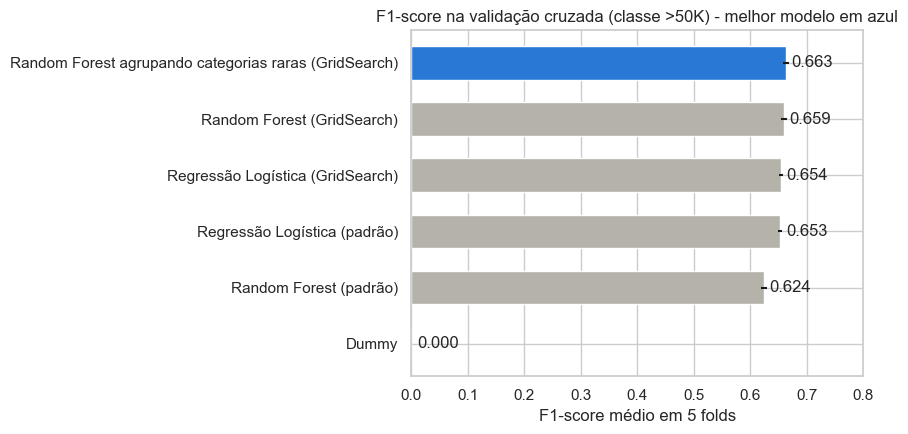

In [11]:
# Comparação visual de todos os modelos da Seção 1 (barras = F1 médio; traço = desvio padrão entre os folds).
tabela_plot = tabela_resultados.sort_values('F1 médio (CV)')
cores = [AZUL if nome == tabela_plot.index[-1] else CINZA for nome in tabela_plot.index]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(tabela_plot.index, tabela_plot['F1 médio (CV)'], xerr=tabela_plot['desvio padrão'], color=cores, height=0.6)
for i, valor in enumerate(tabela_plot['F1 médio (CV)']):
    ax.text(valor + 0.01, i, f'{valor:.3f}', va='center')
ax.set_xlim(0, 0.8)
ax.set_title('F1-score na validação cruzada (classe >50K) - melhor modelo em azul')
ax.set_xlabel('F1-score médio em 5 folds')
plt.tight_layout()
plt.show()

**Interpretação**

- **Categorias agrupadas:** 42 no total. São 38 de `native_country` (só Estados Unidos, México, Filipinas e Alemanha têm 100 pessoas ou mais e continuam como colunas próprias), *Never-worked* e *Without-pay* em `workclass`, *Married-AF-spouse* em `marital_status` e *Armed-Forces* em `occupation`. A saída do pipeline cai de **89 para 51 colunas**.
- **Desempenho:** o F1 foi de 0,659 para **0,663**, com os mesmos hiperparâmetros (`max_depth=None`, `min_samples_leaf=5`, 100 árvores). O ganho é pequeno, menor que o desvio entre os folds (0,006). Na prática, o desempenho é o mesmo com um modelo 43% menor. A hipótese se confirmou: as categorias raras acrescentavam colunas sem informação útil.
- **Melhor modelo da Seção 1: Random Forest com categorias raras agrupadas.** Tem o maior F1 médio na validação cruzada e é o modelo mais simples entre as Random Forests.
- O gráfico resume a seção: o Dummy fica em zero, a Random Forest padrão perde para a Regressão Logística por sobreajuste e, depois de ajustada, passa à frente por uma margem pequena.

In [12]:
# Melhor modelo da Seção 1: Random Forest com categorias raras agrupadas, já retreinado com todo o treino pelo GridSearchCV.
melhor_modelo = grid_rf_agrupado.best_estimator_
melhor_modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age','workclass','fnlwgt',...,'race','sex','native_country']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to se

### 1.5 Curva de aprendizado do melhor modelo

A curva de aprendizado treina o melhor modelo com frações crescentes do treino (10% a 100%) e mede o F1 no próprio treino e na validação cruzada. Ela responde a duas perguntas: o modelo está sobreajustado (distância entre as curvas) e mais dados ajudariam (a curva de validação ainda sobe)?

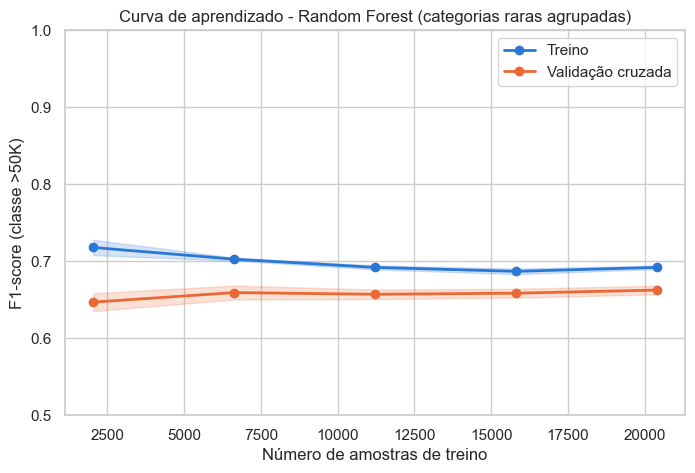

,amostras,F1 treino,F1 validação
0,2040,0.718,0.647
1,6631,0.703,0.659
2,11222,0.692,0.657
3,15813,0.687,0.659
4,20404,0.692,0.663


In [13]:
tamanhos, f1_treino, f1_validacao = learning_curve(
    melhor_modelo, X_train, y_train, cv=cv, scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1
)

fig, ax = plt.subplots(figsize=(8, 5))
for scores, cor, rotulo in [(f1_treino, AZUL, 'Treino'), (f1_validacao, LARANJA, 'Validação cruzada')]:
    media, desvio = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(tamanhos, media, 'o-', color=cor, lw=2, label=rotulo)
    ax.fill_between(tamanhos, media - desvio, media + desvio, color=cor, alpha=0.2)  # faixa = +/- 1 desvio padrão
ax.set_title('Curva de aprendizado - Random Forest (categorias raras agrupadas)')
ax.set_xlabel('Número de amostras de treino')
ax.set_ylabel('F1-score (classe >50K)')
ax.set_ylim(0.5, 1.0)
ax.legend()
plt.show()

display(pd.DataFrame({'amostras': tamanhos, 'F1 treino': f1_treino.mean(axis=1),
                      'F1 validação': f1_validacao.mean(axis=1)}).round(3))

**Interpretação**

- **Distância entre as curvas:** com todos os dados, o F1 de treino (0,692) fica só 0,03 acima do de validação (0,663). O sobreajuste é **pequeno**, graças ao `min_samples_leaf=5`; compare com o 0,624 da Random Forest padrão, que decorava o treino.
- **Tendência:** a validação sobe de 0,647 para cerca de 0,66 até ~7 mil amostras e depois quase não muda. As duas curvas ficam próximas e estáveis num nível modesto. Esse é o sinal de que **mais linhas do mesmo tipo não ajudariam**: o limite está na informação que as features carregam (viés do modelo), e não na quantidade de dados. A Seção 4 discute a principal causa disso.
- As faixas de desvio padrão são estreitas: o resultado é estável entre os folds.

## 2. Avaliação do melhor modelo no conjunto de teste

O conjunto de teste (20% dos dados, 6.377 pessoas) não foi usado em nenhuma decisão até aqui. O melhor modelo foi treinado com todo o treino e agora é avaliado uma única vez no teste. A previsão usa o limiar padrão de 0,5 sobre a probabilidade estimada.

In [14]:
y_pred = melhor_modelo.predict(X_test)               # classe prevista (0 ou 1)
y_proba = melhor_modelo.predict_proba(X_test)[:, 1]  # probabilidade estimada de >50K

metricas_teste = pd.Series({
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_proba),
})
display(metricas_teste.to_frame('conjunto de teste').round(3))
print(f'F1 na validação cruzada: {grid_rf_agrupado.best_score_:.3f} | F1 no teste: {metricas_teste["F1-score"]:.3f}')

,conjunto de teste
Accuracy,0.780
Precision,0.527
Recall,0.831
F1-score,0.645
ROC-AUC,0.885


F1 na validação cruzada: 0.663 | F1 no teste: 0.645


**Interpretação**

- **F1 no teste = 0,645**, um pouco abaixo do F1 da validação cruzada (0,663). Há dois motivos:
  1. **Otimismo da seleção:** escolhemos a configuração com maior F1 na validação entre 29 testadas (5 da Regressão Logística e 12 + 12 da Random Forest). A melhor entre muitas tende a ter tido um pouco de "sorte" nos folds, então a nota da validação fica levemente otimista. O teste não participou da escolha e dá a estimativa honesta.
  2. **Variação da amostra:** o teste é uma amostra de 6.377 pessoas, e outra amostra daria um F1 um pouco diferente.
- **Recall = 0,831:** o modelo encontra 83% das pessoas que ganham `>50K`.
- **Precision = 0,527:** das pessoas que o modelo aponta como `>50K`, só pouco mais da metade realmente ganha. É o efeito esperado do `class_weight='balanced'`: o modelo prefere errar para o lado de `>50K` a deixar passar alguém dessa classe.
- **Accuracy = 0,780**, só 2 pontos acima do Dummy (0,759). Isso **não** quer dizer que o modelo é quase inútil: o Dummy não encontra ninguém da classe `>50K`, e o modelo encontra 83%. O balanceamento troca acertos na classe majoritária por recall na minoritária, o que reduz a acurácia e aumenta o F1. É mais uma razão para a acurácia não ser a métrica de escolha.

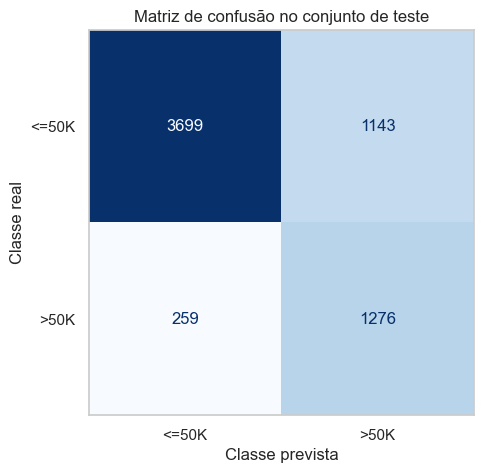

Verdadeiros negativos (<=50K corretos): 3699
Falsos positivos (previsto >50K, real <=50K): 1143
Falsos negativos (previsto <=50K, real >50K): 259
Verdadeiros positivos (>50K corretos): 1276


In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['<=50K', '>50K'],
                                        cmap='Blues', values_format='d', colorbar=False, ax=ax)
ax.set_title('Matriz de confusão no conjunto de teste')
ax.set_xlabel('Classe prevista')
ax.set_ylabel('Classe real')
ax.grid(False)
plt.show()

vn, fp, fn, vp = confusion_matrix(y_test, y_pred).ravel()
print(f'Verdadeiros negativos (<=50K corretos): {vn}')
print(f'Falsos positivos (previsto >50K, real <=50K): {fp}')
print(f'Falsos negativos (previsto <=50K, real >50K): {fn}')
print(f'Verdadeiros positivos (>50K corretos): {vp}')

**Interpretação da matriz de confusão**

- **Verdadeiros negativos (3.699) e verdadeiros positivos (1.276):** acertos nas duas classes.
- **Falsos positivos (1.143):** pessoas com renda `<=50K` classificadas como `>50K`. É o erro mais comum, 4,4 vezes o número de falsos negativos, e é ele que derruba a precision. Corresponde a 24% das pessoas `<=50K` (1.143 / 4.842).
- **Falsos negativos (259):** pessoas com renda `>50K` que o modelo não encontrou, 17% da classe positiva (259 / 1.535).
- O predomínio de falsos positivos é consequência do `class_weight='balanced'`. Se numa aplicação real o falso positivo fosse mais caro, bastaria aumentar o limiar de decisão (acima de 0,5) para trocar recall por precision.

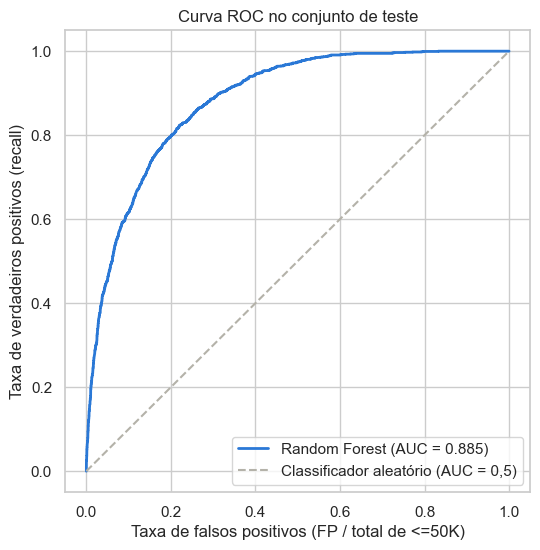

In [16]:
# A curva ROC varia o limiar de decisão de 1 a 0 e marca, para cada limiar, a taxa de FP (eixo x) e o recall (eixo y).
taxa_fp, taxa_vp, limiares = roc_curve(y_test, y_proba)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(taxa_fp, taxa_vp, color=AZUL, lw=2, label=f'Random Forest (AUC = {metricas_teste["ROC-AUC"]:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color=CINZA, label='Classificador aleatório (AUC = 0,5)')
ax.set_title('Curva ROC no conjunto de teste')
ax.set_xlabel('Taxa de falsos positivos (FP / total de <=50K)')
ax.set_ylabel('Taxa de verdadeiros positivos (recall)')
ax.legend(loc='lower right')
plt.show()

**Interpretação da curva ROC**

- **ROC-AUC = 0,885:** se sortearmos uma pessoa `>50K` e uma `<=50K`, em 88,5% das vezes o modelo dá probabilidade maior à primeira. Um classificador aleatório teria 0,5 (linha tracejada) e um perfeito, 1,0.
- A curva sobe rápido perto da origem: dá para obter um recall razoável com poucos falsos positivos. Cada ponto da curva é um limiar diferente. O limiar de 0,5 usado acima corresponde ao ponto com taxa de falsos positivos de 0,24 e recall de 0,83.
- A AUC avalia a **ordenação** das pessoas pela probabilidade, sem depender do limiar; o F1 avalia o limiar escolhido. Por isso as duas métricas se complementam.

### 2.1 Desempenho por sexo e raça

A Etapa 1 encontrou um viés de sexo nos dados (31% dos homens ganham `>50K`, contra 11% das mulheres) e recomendou comparar as métricas entre homens e mulheres. Fazemos isso também para raça: para cada grupo do teste, comparamos a taxa real de `>50K`, a taxa prevista pelo modelo, o recall e a precision.

In [17]:
teste_grupos = X_test[['sex', 'race']].assign(real=y_test.values, previsto=y_pred)


def metricas_grupo(df):
    return pd.Series({
        'pessoas': len(df),
        '% real >50K': df['real'].mean() * 100,
        '% previsto >50K': df['previsto'].mean() * 100,
        'recall': recall_score(df['real'], df['previsto']),
        'precision': precision_score(df['real'], df['previsto'], zero_division=0),
    })


for col in ['sex', 'race']:
    display(teste_grupos.groupby(col)[['real', 'previsto']].apply(metricas_grupo).round(2))

,pessoas,% real >50K,% previsto >50K,recall,precision
sex,,,,,
Female,2098.0,11.39,14.49,0.67,0.53
Male,4279.0,30.29,49.43,0.86,0.53


,pessoas,% real >50K,% previsto >50K,recall,precision
race,,,,,
Amer-Indian-Eskimo,67.0,5.97,16.42,0.50,0.18
Asian-Pac-Islander,214.0,25.23,37.38,0.81,0.55
Black,561.0,12.66,18.54,0.79,0.54
Other,45.0,11.11,13.33,0.60,0.50
White,5490.0,25.52,40.40,0.84,0.53


**Interpretação**

- **Sexo:** o modelo prevê `>50K` para 49,4% dos homens, contra uma taxa real de 30,3%, e para 14,5% das mulheres, contra 11,4% reais. O **recall das mulheres é bem menor (0,67 contra 0,86)**: uma mulher que ganha `>50K` tem mais chance de não ser encontrada pelo modelo. A precision é igual nos dois grupos (0,53).
- **Raça:** *White*, *Asian-Pac-Islander* e *Black* têm recall entre 0,79 e 0,84 e precision de 0,53 a 0,55. Os grupos *Amer-Indian-Eskimo* (67 pessoas, só 4 com `>50K`) e *Other* (45 pessoas, 5 com `>50K`) são pequenos demais: métricas como a precision de 0,18 dependem de poucos casos e não permitem conclusões.
- Portanto, o desempenho do modelo **não é igual entre homens e mulheres**. A Seção 4 discute a causa e o que fazer.

## 3. Interpretação e explicabilidade

### 3.1 Modelo linear: coeficientes da Regressão Logística

Usamos a Regressão Logística ajustada no `GridSearchCV` (pipeline original). Cada coeficiente indica quanto a feature muda o *log-odds* de `>50K`: positivo aumenta a chance, negativo diminui. Como as numéricas foram padronizadas e as categóricas são 0/1, as magnitudes são comparáveis. `e^coef` é o *odds ratio*: o fator que multiplica a chance de `>50K` quando a feature aumenta 1 unidade (1 desvio padrão nas numéricas, ou passar de 0 para 1 numa categoria).

,coeficiente,odds ratio (e^coef)
native_country_Columbia,-2.290,0.101
marital_status_Married-AF-spouse,2.141,8.508
occupation_Priv-house-serv,-2.105,0.122


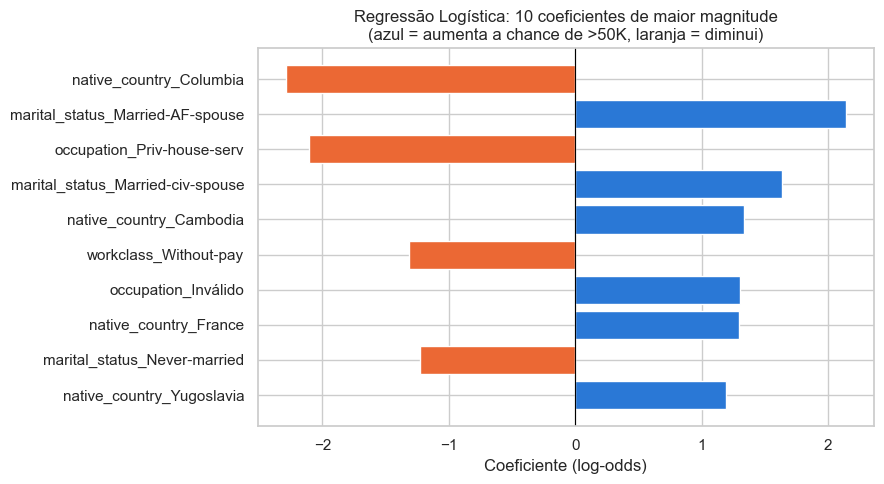

In [18]:
lr_final = grid_lr.best_estimator_
coeficientes = pd.Series(lr_final.named_steps['classifier'].coef_[0],
                         index=lr_final.named_steps['preprocessor'].get_feature_names_out())
top_coef = coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index).head(10)

display(pd.DataFrame({'coeficiente': top_coef.head(3), 'odds ratio (e^coef)': np.exp(top_coef.head(3))}).round(3))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_coef.index[::-1], top_coef.values[::-1], color=[AZUL if c > 0 else LARANJA for c in top_coef.values[::-1]])
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Regressão Logística: 10 coeficientes de maior magnitude\n(azul = aumenta a chance de >50K, laranja = diminui)')
ax.set_xlabel('Coeficiente (log-odds)')
plt.tight_layout()
plt.show()

**Interpretação dos 3 coeficientes de maior magnitude**

Os três maiores coeficientes são de **categorias raríssimas**:

1. **`native_country_Columbia` (−2,29; odds ratio 0,10):** 45 pessoas no treino, só 1 com `>50K` (2%).
2. **`marital_status_Married-AF-spouse` (+2,14; odds ratio 8,5):** casados com cônjuge nas Forças Armadas. São só 17 pessoas no treino, 7 com `>50K` (41%).
3. **`occupation_Priv-house-serv` (−2,10; odds ratio 0,12):** empregados domésticos. São 115 pessoas, só 1 com `>50K` (menos de 1%).

**O que isso mostra:**

- **Coeficiente grande não significa feature importante.** Cada uma dessas colunas vale 1 para poucas dezenas de pessoas. Como nesses grupos quase todos estão numa só classe, o modelo empurra o coeficiente para valores extremos.
- **Esses coeficientes são instáveis.** Com tão poucas pessoas, uma ou duas a mais com renda alta mudariam muito o valor. O `GridSearchCV` escolheu `C = 10`, a regularização mais fraca, que pouco penaliza coeficientes grandes; com `C = 0,1` o F1 era praticamente o mesmo (0,653) e os coeficientes seriam menores.
- É o mesmo problema que motivou a mudança da Seção 1.4: categorias raras geram colunas que o modelo usa para decorar poucos casos.
- **Entre as categorias frequentes**, o maior coeficiente é `marital_status_Married-civ-spouse` (+1,64; odds ratio 5,1): ser casado(a) no civil multiplica por cerca de 5 a chance de `>50K`, mantidas as demais variáveis. É coerente com a EDA (45% dos casados ganham `>50K`, contra 6% dos não casados) e com o 1º lugar dessa feature na Random Forest e no SHAP, a seguir. Coeficiente mede associação, não causa: casar não aumenta a renda; o casamento está associado a mais idade e estabilidade profissional.

### 3.2 Modelo ensemble: importância das features na Random Forest

Usamos o melhor modelo (Random Forest com categorias raras agrupadas). A importância de cada feature (`feature_importances_`) é a redução média de impureza de Gini que as divisões com essa feature produzem, somada em todas as árvores e normalizada para somar 1. Ela mostra **quanto** a feature é usada, mas não o sentido do efeito.

,importância
marital_status_Married-civ-spouse,0.175
education_num,0.163
age,0.118


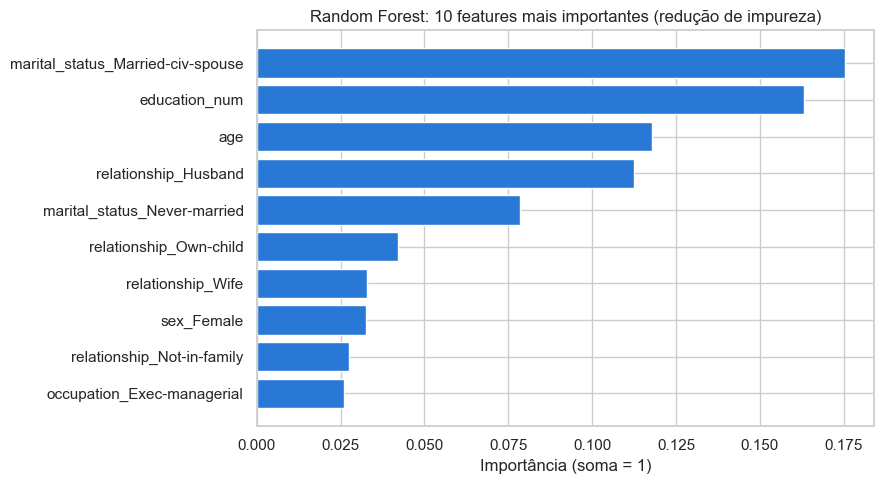

In [19]:
rf_final = melhor_modelo.named_steps['classifier']
nomes_features = melhor_modelo.named_steps['preprocessor'].get_feature_names_out()
importancias = pd.Series(rf_final.feature_importances_, index=nomes_features).sort_values(ascending=False)

display(importancias.head(3).to_frame('importância').round(3))

fig, ax = plt.subplots(figsize=(9, 5))
top_imp = importancias.head(10)[::-1]
ax.barh(top_imp.index, top_imp.values, color=AZUL)
ax.set_title('Random Forest: 10 features mais importantes (redução de impureza)')
ax.set_xlabel('Importância (soma = 1)')
plt.tight_layout()
plt.show()

**Interpretação das 3 features mais importantes**

1. **`marital_status_Married-civ-spouse` (0,175):** muitas árvores começam separando casados de não casados, os dois grupos com taxas de `>50K` mais diferentes (45% contra 6%).
2. **`education_num` (0,163):** a numérica mais ligada à renda na EDA (correlação de 0,34). A taxa de `>50K` vai de menos de 8% sem ensino médio completo a 74% no doutorado.
3. **`age` (0,118):** a relação com a renda **não é linear**. A taxa de `>50K` sobe de 2% (até 25 anos) para 40% (45 a 55 anos) e depois cai para 21% (acima de 65). A floresta captura esse "sobe e desce" com cortes em vários pontos; um modelo linear só enxerga uma inclinação única.

**Comparação com a Regressão Logística:** aqui as categorias raras não aparecem no topo. A importância por impureza depende de quantas pessoas cada divisão afeta, então uma coluna que vale 1 para 17 pessoas quase não reduz a impureza. Em 4º lugar está `relationship_Husband` (0,112), que equivale praticamente a "homem casado".

**Cuidados na leitura:** a importância por impureza não indica o **sentido** do efeito (por isso usamos SHAP a seguir) e tende a favorecer variáveis numéricas com muitos valores possíveis, como `age`, que oferecem mais pontos de corte.

### 3.3 SHAP no melhor modelo

O SHAP distribui a previsão de cada pessoa entre as features, com base nos valores de Shapley da teoria dos jogos: **previsão = valor base + soma das contribuições SHAP**. O valor base é o ponto de partida da decomposição: em modelos de árvores, ele vem da distribuição das classes na raiz das árvores, ponderada pelo `class_weight`. Diferente da importância da Seção 3.2, o SHAP mostra o **sentido** do efeito e funciona para cada previsão individual.

Usamos o `TreeExplainer`, que calcula os valores exatos para modelos de árvores, em uma amostra aleatória de 200 pessoas do teste (o cálculo na Random Forest é lento; 200 pontos bastam para o padrão global). As contribuições se referem à probabilidade da classe `>50K`. Nos gráficos, as numéricas aparecem com os valores originais (idade em anos etc.), e não padronizados, para facilitar a leitura.

In [20]:
preprocessador = melhor_modelo.named_steps['preprocessor']
indices_amostra = X_test.sample(200, random_state=RANDOM_STATE).index
X_amostra = pd.DataFrame(preprocessador.transform(X_test.loc[indices_amostra]),
                         columns=nomes_features, index=indices_amostra)

explainer = shap.TreeExplainer(rf_final)
shap_values = explainer(X_amostra)[:, :, 1]  # contribuições para a probabilidade da classe >50K

# Troca os valores padronizados das numéricas pelos originais, só para exibição nos gráficos.
colunas_numericas = numeric_features
valores_exibicao = X_amostra.copy()
valores_exibicao[colunas_numericas] = X_test.loc[indices_amostra, colunas_numericas].values
shap_values.data = valores_exibicao.values

print('Valor base da decomposição SHAP (classe >50K):', round(float(shap_values.base_values[0]), 3))

Valor base da decomposição SHAP (classe >50K): 0.5


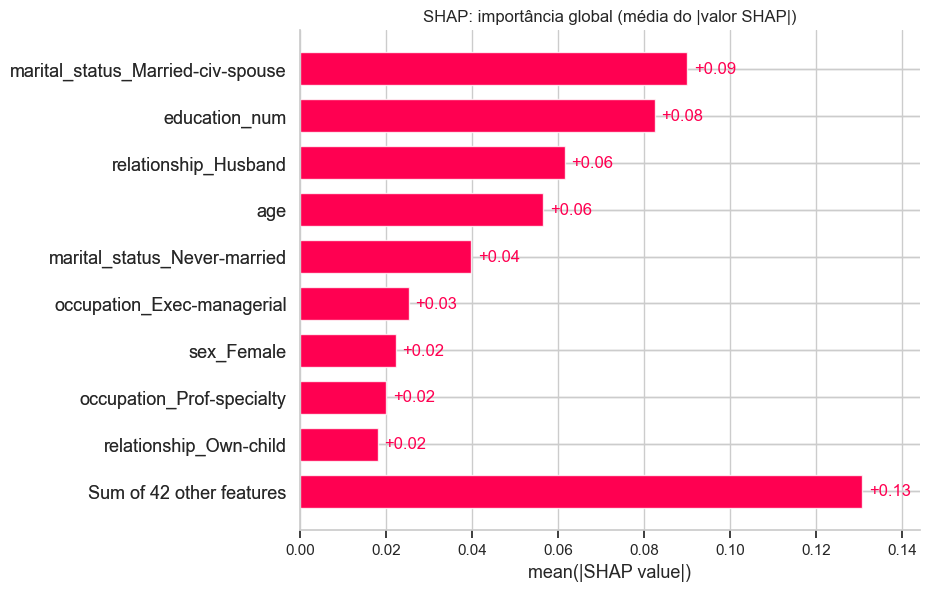

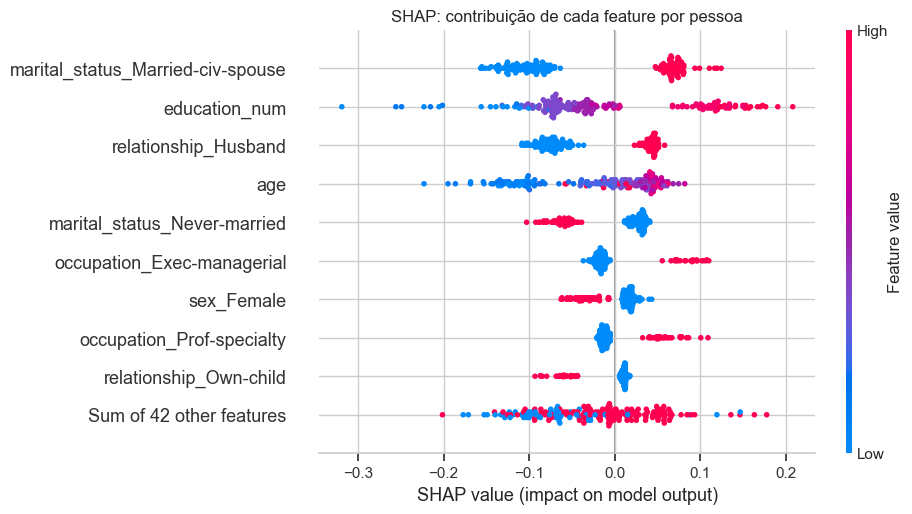

In [21]:
# Importância global: média do |SHAP| de cada feature.
shap.plots.bar(shap_values, max_display=10, show=False)
plt.title('SHAP: importância global (média do |valor SHAP|)')
plt.show()

# Beeswarm: cada ponto é uma pessoa; posição = contribuição, cor = valor da feature.
shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.title('SHAP: contribuição de cada feature por pessoa')
plt.show()

**Interpretação da importância global (SHAP)**

- **Valor base = 0,5:** com `class_weight='balanced'`, as duas classes têm peso total igual no treino, então a raiz das árvores fica em 50/50 e a decomposição parte de 0,5. Esse valor é a proporção imposta no treino, e **não** a média das probabilidades previstas: na média, as contribuições das features somam um valor negativo, porque a maioria das pessoas tem perfil de `<=50K`.
- **Ranking:** `marital_status_Married-civ-spouse` (contribuição média de 0,09), `education_num` (0,08), `relationship_Husband` e `age` (0,06), `marital_status_Never-married` (0,04) e `occupation_Exec-managerial` (0,03). São as mesmas features do topo da importância da Seção 3.2, o que dá confiança de que o modelo realmente se apoia nelas.
- **Sentido dos efeitos** (beeswarm; vermelho = valor alto, azul = valor baixo):
  - ser casado (vermelho) soma cerca de +0,07 à probabilidade; não ser casado (azul) subtrai cerca de 0,1;
  - `education_num` tem os **maiores efeitos individuais**: escolaridade alta soma até +0,2, e escolaridade muito baixa subtrai até −0,3;
  - ser jovem (azul em `age`) reduz a probabilidade em até −0,2;
  - ocupações de executivo e de especialista (`Exec-managerial`, `Prof-specialty`) somam de +0,05 a +0,1;
  - `sex_Female`: ser mulher (vermelho) subtrai cerca de 0,05. **O modelo usa o sexo diretamente**, o que é retomado na Seção 4.

#### Explicação de 3 predições individuais

Escolhemos, dentro da amostra, três casos que cobrem situações diferentes:

1. o **verdadeiro positivo** com maior probabilidade prevista (acerto em `>50K`);
2. o **verdadeiro negativo** com menor probabilidade prevista (acerto em `<=50K`);
3. o **falso positivo** com maior probabilidade prevista, ou seja, o erro em que o modelo estava mais confiante.

In [22]:
proba_amostra = rf_final.predict_proba(X_amostra.values)[:, 1]
pred_amostra = (proba_amostra >= 0.5).astype(int)
real_amostra = y_test.loc[indices_amostra].values


def posicao(mascara, maior=True):
    # Posição, na amostra, da pessoa com maior (ou menor) probabilidade entre as que satisfazem a máscara.
    candidatos = np.where(mascara)[0]
    return candidatos[np.argmax(proba_amostra[candidatos])] if maior else candidatos[np.argmin(proba_amostra[candidatos])]


casos = {
    'Caso 1 - verdadeiro positivo': posicao((pred_amostra == 1) & (real_amostra == 1)),
    'Caso 2 - verdadeiro negativo': posicao((pred_amostra == 0) & (real_amostra == 0), maior=False),
    'Caso 3 - falso positivo': posicao((pred_amostra == 1) & (real_amostra == 0)),
}

# Dados originais das três pessoas.
tabela_casos = X_test.loc[indices_amostra[list(casos.values())]].drop(columns=['fnlwgt', 'education'])
tabela_casos.insert(0, 'caso', list(casos))
tabela_casos['renda real'] = np.where(real_amostra[list(casos.values())] == 1, '>50K', '<=50K')
tabela_casos['prob. prevista >50K'] = proba_amostra[list(casos.values())].round(3)
display(tabela_casos.set_index('caso').T)

caso,Caso 1 - verdadeiro positivo,Caso 2 - verdadeiro negativo,Caso 3 - falso positivo
age,53,19,49
workclass,Private,Private,Private
education_num,13,9,13
marital_status,Married-civ-spouse,Never-married,Married-civ-spouse
occupation,Inválido,Handlers-cleaners,Exec-managerial
relationship,Husband,Own-child,Husband
race,White,White,White
sex,Male,Female,Male
native_country,United-States,United-States,United-States
renda real,>50K,<=50K,<=50K


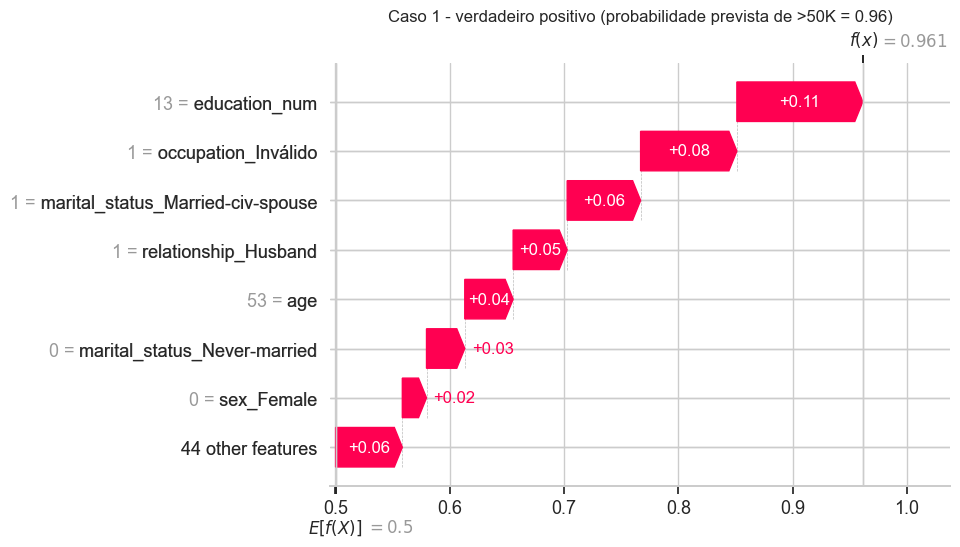

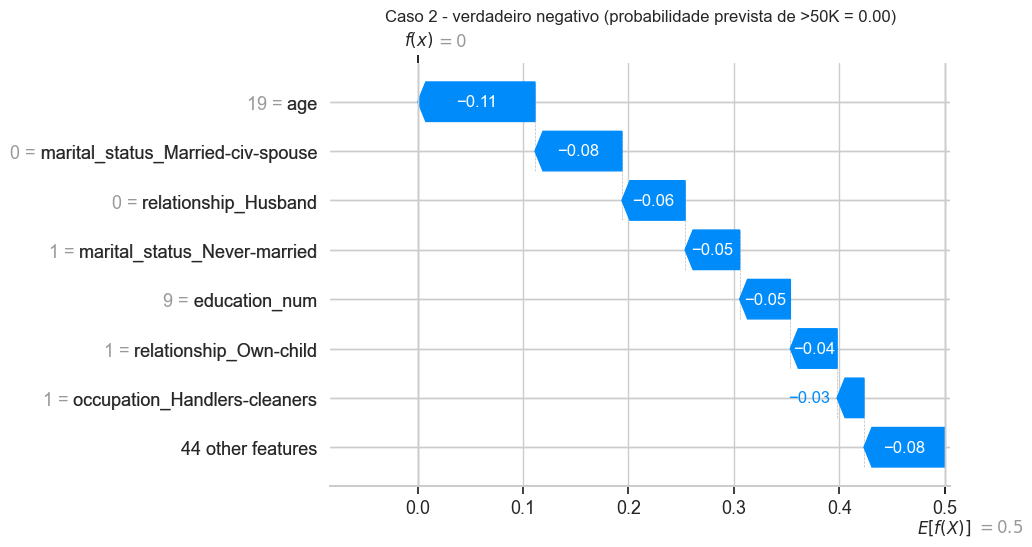

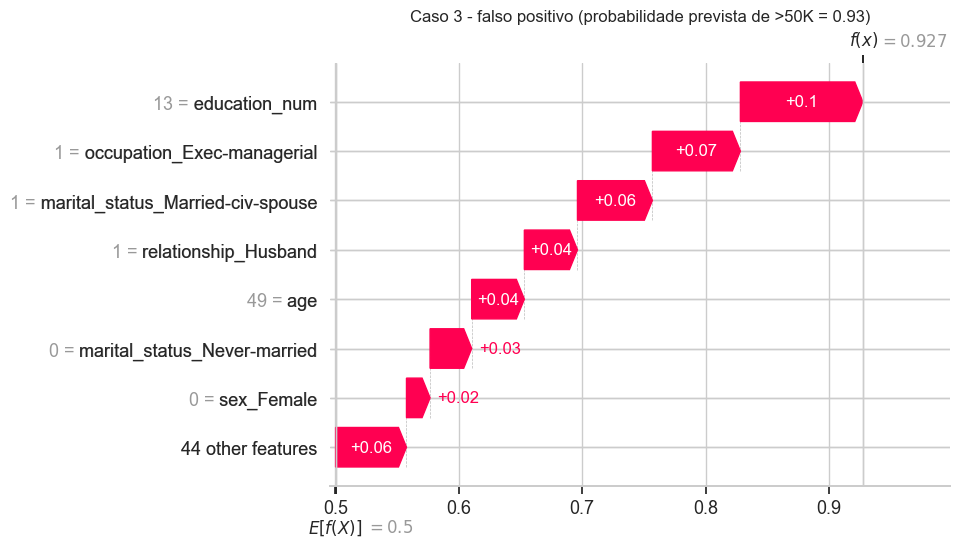

In [23]:
for titulo, i in casos.items():
    shap.plots.waterfall(shap_values[i], max_display=8, show=False)
    plt.title(f'{titulo} (probabilidade prevista de >50K = {proba_amostra[i]:.2f})')
    plt.show()

**Interpretação das 3 predições** (o gráfico começa no valor base 0,5, embaixo, e cada barra soma ou subtrai a contribuição de uma feature até chegar à probabilidade prevista, em cima)

**Caso 1: verdadeiro positivo (homem, 53 anos, probabilidade de 0,96).** A graduação (13 = bacharelado) soma +0,11. Em seguida vem `occupation_Inválido` (+0,08), seguido de ser casado, marido e ter 53 anos. Chama atenção a segunda contribuição: `Inválido` é o grupo de 1.462 linhas com o texto "occupation" no lugar da ocupação, que tem 54% de renda alta no treino. O modelo aprendeu esse **erro do arquivo** como um sinal forte de renda alta. Como a EDA já alertava, esse efeito não vale para dados novos.

**Caso 2: verdadeiro negativo (mulher, 19 anos, probabilidade de 0,00).** A idade é o fator decisivo (−0,11). Depois vêm não ser casada (−0,08), não ser marido (−0,06), nunca ter casado (−0,05), ter só o ensino médio (9 = *HS-grad*, −0,05), ser filha na família (`Own-child`) e trabalhar com limpeza (`Handlers-cleaners`). É o perfil típico de uma jovem em início de vida profissional, e todas as features apontam para `<=50K`.

**Caso 3: falso positivo (homem, 49 anos, renda real `<=50K`, probabilidade de 0,93).** É o erro em que o modelo estava mais confiante. A pessoa tem o perfil mais associado a renda alta: graduação (+0,10), cargo executivo (`Exec-managerial`, +0,07), casado e marido, 49 anos. Nada nos dados indica renda baixa, então o modelo erra. A explicação está em informações que esta versão do dataset não tem, como horas trabalhadas por semana, ganhos de capital, porte da empresa e região. Esse tipo de erro não se corrige trocando o algoritmo, só com features novas.

## 4. Discussão crítica

### 4.1 Limitações do melhor modelo

**1. O modelo reproduz o viés de sexo dos dados, e simplesmente retirar a coluna `sex` não resolveria.** O SHAP mostra que ser mulher reduz a probabilidade prevista, e a Seção 2.1 mostra o efeito: recall de 0,67 para mulheres contra 0,86 para homens. A solução ingênua seria retirar `sex` do pipeline, estratégia chamada de *fairness through unawareness*. Ela falha quando existem **variáveis substitutas** (*proxies*). Aqui, `relationship` revela o sexo quase perfeitamente: na base (após remover duplicatas), dos 12.912 registros com `Husband`, 12.911 são homens, e dos 1.531 com `Wife`, 1.530 são mulheres. E `relationship_Husband` está entre as 4 features mais importantes do modelo. Tratar o problema de verdade exige escolher um critério formal de justiça, como a igualdade de oportunidade (mesmo recall entre os grupos), e intervir no treino ou usar limiares diferentes por grupo.

**2. As probabilidades não são calibradas e o limiar de 0,5 é arbitrário.** As probabilidades estão infladas pelo `class_weight='balanced'`: com as classes igualadas no treino, a decomposição do SHAP parte de 0,5, e o modelo aponta `>50K` para 37,9% das pessoas do teste (2.419 de 6.377, Seção 2), contra uma taxa real de 24%. Além disso, florestas aleatórias tendem a produzir probabilidades mal calibradas, afastadas de 0 e de 1. Na prática, uma saída de 0,7 **não** significa 70% de chance de ganhar `>50K`. Se o uso exigir probabilidades confiáveis, seria preciso calibrar o modelo (por exemplo, com `CalibratedClassifierCV`) e escolher o limiar pelo custo real de cada tipo de erro, em vez de fixá-lo em 0,5. Com precision de 0,53, por exemplo, quase metade dos alertas de `>50K` é falsa.

### 4.2 Limitações dos dados

**1. Faltam variáveis importantes nesta versão do dataset.** O *Adult* original da UCI tem 14 atributos, entre eles `capital-gain`, `capital-loss` e `hours-per-week`. A versão do Kaggle usada aqui tem só 11 e não traz essas três. São justamente variáveis ligadas diretamente à renda: rendimentos de investimentos e jornada de trabalho, que separa quem trabalha meio período de quem trabalha em tempo integral. Sem elas, o modelo depende de sinais indiretos, como estado civil e idade. A curva de aprendizado (Seção 1.5) mostra a consequência: treino e validação se estabilizam perto de 0,66–0,69, então o limite está na informação disponível, e não na quantidade de linhas. O Caso 3 do SHAP é um exemplo concreto.

**2. Os dados são de 1994 e o limiar de renda é nominal.** US$ 50 mil em 1994 equivalem a mais de US$ 100 mil em valores atuais, pela correção do índice de preços ao consumidor americano. Em 30 anos também mudaram a participação feminina no mercado de trabalho, a escolaridade média e a remuneração de cada ocupação. O modelo aprendeu um retrato de 1994 e não pode ser aplicado diretamente a dados atuais. É um caso de *concept drift*: a relação entre as features e o alvo muda com o tempo.

### 4.3 Operacionalização e manutenção

**1. Publicar o pipeline completo, versionado e documentado.** Salvar `melhor_modelo` (pré-processamento + Random Forest) num único arquivo com `joblib`, junto com a versão do scikit-learn, a lista de colunas esperadas e as métricas de validação. Como o pré-processamento está dentro do pipeline, o uso em produção aplica exatamente as mesmas transformações do treino, sem código duplicado. Isso reduz a dívida técnica típica de sistemas de ML, em que manter o sistema custa mais que desenvolvê-lo. O modelo deve ser acompanhado de um *model card* com o uso pretendido, as métricas por grupo (Seção 2.1) e as limitações desta seção.

**2. Monitorar os dados e o desempenho e retreinar periodicamente.** Em produção, é preciso:

- comparar a distribuição das features novas com a do treino: média de idade e de escolaridade, proporção de pessoas nas colunas `infrequent` e frequência da categoria `Inválido`, que vem de um erro do arquivo e não deveria aparecer em dados novos. Se a coleta for corrigida, o modelo precisa ser retreinado sem ela;
- quando a renda real for conhecida, recalcular F1, recall e precision, no geral e **por sexo e raça**;
- retreinar com dados recentes quando houver queda de desempenho ou mudança nas distribuições, como se recomenda para sistemas sujeitos a *concept drift*.

## 5. Conclusão

| Modelo | F1 na validação cruzada |
|---|---|
| Dummy (`most_frequent`) | 0,000 |
| Regressão Logística ajustada (`C = 10`) | 0,654 |
| Random Forest ajustada (89 colunas) | 0,659 |
| **Random Forest com categorias raras agrupadas** (51 colunas; `max_depth=None`, `min_samples_leaf=5`, 100 árvores) | **0,663** |

- O **melhor modelo** é a Random Forest com categorias raras agrupadas. No conjunto de teste ela teve F1 = 0,645, recall = 0,831, precision = 0,527, accuracy = 0,780 e ROC-AUC = 0,885.
- O hiperparâmetro decisivo foi `min_samples_leaf`: com o padrão (1), a Random Forest sobreajusta e perde para a Regressão Logística; com 5, passa à frente por uma margem pequena.
- A mudança no pipeline (agrupar categorias com menos de 100 pessoas) reduziu a entrada de 89 para 51 colunas, com F1 igual ou um pouco melhor.
- Nos três métodos de interpretação, as variáveis que mais pesam são estado civil (casado), escolaridade, idade e papel na família (`Husband`). Na Regressão Logística, os maiores coeficientes são de categorias raríssimas, o que é instabilidade, e não importância.
- As principais limitações são o viés de sexo, que remover a coluna não resolveria por causa de `relationship`, e a ausência de ganho de capital e de horas trabalhadas nesta versão dos dados, que limita o desempenho.
- **Próximos passos:** ajustar o limiar de decisão e calibrar as probabilidades; medir e tratar critérios formais de justiça; testar outros ensembles, como *gradient boosting*; usar uma versão dos dados com todas as variáveis do Censo.